## Exploring Dataset

Note: The dataset pdf is uploaded into GitHub in the same repository under "anes_timeseries_2024_userguidecodebook_20260519.pdf"

### Importing and Fixing CSV

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
voting = pd.read_csv('voting.csv')

/var/folders/wm/bgmwdbq9011gtbp_0mcf_wjw0000gn/T/ipykernel_23037/3220322533.py:5: DtypeWarning: Columns (8: V240101a, 10: V240101c, 11: V240101d, 16: V240103a, 18: V240103c, 19: V240103d, 20: V240104a, 22: V240104c, 23: V240104d, 24: V240105a, 26: V240105c, 27: V240105d, 28: V240106a, 30: V240106c, 31: V240106d, 36: V240108a, 38: V240108c, 39: V240108d, 1464: V243002, 1465: V243003, 1466: V243004, 1467: V243005, 1468: V243006, 1471: V243009, 1472: V243050, 1473: V243051, 1474: V243052, 1475: V243053, 1479: V243056, 1480: V243057, 1481: V243058) have mixed types. Specify dtype option on import or set low_memory=False.
  voting = pd.read_csv('voting.csv')


In [2]:
newvoting = voting.rename(columns={
    "V240001": "respondent_id", "V241458x": "age", "V241551": "gender",
    "V240002c": "interview_completion_status",
    "V241550": "sex", "V241501x": "race_ethnicity", "V241463": "education",
    "V241227x": "party_identification","V241042": "intention_to_vote",
    "V241043": "intended_presidential_candidate","V241039": "early_vote_candidate",
    "V242065": "reported_turnout","V242067": "actual_presidential_candidate"
})

newvoting = newvoting[[
    "respondent_id", "age", "gender","interview_completion_status", "sex", "race_ethnicity",
    "education", "party_identification", "intention_to_vote",
    "intended_presidential_candidate", "early_vote_candidate",
    "reported_turnout", "actual_presidential_candidate"
]]

newvoting.head()

,respondent_id,age,gender,interview_completion_status,sex,race_ethnicity,education,party_identification,intention_to_vote,intended_presidential_candidate,early_vote_candidate,reported_turnout,actual_presidential_candidate
0,140001,50,1,2,1,3,13,7,1,2,-1,4,2
1,140002,41,2,2,2,4,10,4,1,3,-1,3,-1
2,140003,44,2,2,2,1,10,1,1,1,-1,4,1
3,140004,45,1,2,1,4,11,6,1,2,-1,2,-1
4,140005,80,1,2,1,1,16,5,1,2,-1,4,2


The original survey, from the National Science Foundation, was a time series study that looked at voting patterns and behaviors of people  before and after the 2024 election. Pre-election survey had been taken between August 3rd through November 5th of 2024, and post-election surveys were taken from November 7th through Februrary 17th of 2025. The survey guide had stated that most people had done the interview online, with some doing it over video, by mobile phone or face-to-face. The exact breakdown between modes of interview will be shown below.

Column were named with non-descriptive names like "V240001" representing respondants' unique ID. I selected and changed all the important column that will be relevant for the exercise.

In [3]:
value_guide = {
    "respondent_id": "Unique respondent identification number",

    "age": {
        "80": "80 years or older",
        "Other values": "Respondent's age in years"
    },

    "gender": {
        1: "Man",
        2: "Woman",
        3: "Nonbinary",
        4: "Something else"
    },

    "sex": {
        1: "Male",
        2: "Female"
    },

    'interview_completion_status':{
        1: "Did not return for post-election interview",
        2: "Returned for post-election interview"
    },

    "race_ethnicity": {
        1: "White, non-Hispanic",
        2: "Black, non-Hispanic",
        3: "Hispanic",
        4: "Asian/Pacific Islander, non-Hispanic",
        5: "Native American/Alaska Native or other race, non-Hispanic",
        6: "Multiple races, non-Hispanic"
    },

    "education": {
    1: "Less than first grade",
    2: "First through fourth grade",
    3: "Fifth through sixth grade",
    4: "Seventh through eighth grade",
    5: "Ninth grade",
    6: "Tenth grade",
    7: "Eleventh grade",
    8: "Twelfth grade, no diploma",
    9: "High school graduate",
    10: "Some college, no degree",
    11: "Associate degree, occupational/vocational",
    12: "Associate degree, academic",
    13: "Bachelor's degree",
    14: "Master's degree",
    15: "Professional school degree",
    16: "Doctorate",
    95: "Other"
},

    "party_identification": {
        1: "Strong Democrat",
        2: "Not very strong Democrat",
        3: "Independent-Democrat",
        4: "Independent",
        5: "Independent-Republican",
        6: "Not very strong Republican",
        7: "Strong Republican"
    },

    "intention_to_vote": {
        1: "Yes",
        2: "No"
    },

    "intended_presidential_candidate": {
        1: "Kamala Harris",
        2: "Donald Trump",
        3: "Robert F. Kennedy Jr.",
        4: "Cornel West",
        5: "Jill Stein",
        6: "Another candidate"
    },

    "early_vote_candidate": {
        1: "Kamala Harris",
        2: "Donald Trump",
        3: "Robert F. Kennedy Jr.",
        4: "Cornel West",
        5: "Jill Stein",
        6: "Another candidate"
    },

    "reported_turnout": {
        1: "Did not vote",
        2: "Thought about voting but did not",
        3: "Usually votes but did not this time",
        4: "Sure they voted"
    },

    "actual_presidential_candidate": {
        1: "Kamala Harris",
        2: "Donald Trump",
        4: "Cornel West",
        5: "Jill Stein",
        6: "Another candidate"
    }
}

# Common ANES missing-value codes
missing_value_guide = {
    -1: "Inapplicable",
    -2: "Missing information",
    -4: "Error",
    -6: "No post-election interview",
    -7: "Insufficient partial interview",
    -8: "Don't know",
    -9: "Refused"
}

# Replace numerical values with their descriptions

for column, values in value_guide.items():
    if column in newvoting.columns and isinstance(values, dict):
        newvoting[column] = newvoting[column].replace(values)

# Replace common missing-value codes
for column in newvoting.columns:
    newvoting[column] = newvoting[column].replace(missing_value_guide)

The codes above were assisted with AI to translate the number values into words when applicable, like sex being 1/2 instead of male/female or race/ethinicity being a number value rather than a word descriptor. Cleaning this up would save time in the long run, as I would have to rely back to the ANES 2024 Column Value Guide book 

In [4]:
newvoting.head()

,respondent_id,age,gender,interview_completion_status,sex,race_ethnicity,education,party_identification,intention_to_vote,intended_presidential_candidate,early_vote_candidate,reported_turnout,actual_presidential_candidate
0,140001,50,Man,Returned for post-election interview,Male,Hispanic,Bachelor's degree,Strong Republican,Yes,Donald Trump,Inapplicable,Sure they voted,Donald Trump
1,140002,41,Woman,Returned for post-election interview,Female,"Asian/Pacific Islander, non-Hispanic","Some college, no degree",Independent,Yes,Robert F. Kennedy Jr.,Inapplicable,Usually votes but did not this time,Inapplicable
2,140003,44,Woman,Returned for post-election interview,Female,"White, non-Hispanic","Some college, no degree",Strong Democrat,Yes,Kamala Harris,Inapplicable,Sure they voted,Kamala Harris
3,140004,45,Man,Returned for post-election interview,Male,"Asian/Pacific Islander, non-Hispanic","Associate degree, occupational/vocational",Not very strong Republican,Yes,Donald Trump,Inapplicable,Thought about voting but did not,Inapplicable
4,140005,80,Man,Returned for post-election interview,Male,"White, non-Hispanic",Doctorate,Independent-Republican,Yes,Donald Trump,Inapplicable,Sure they voted,Donald Trump


### What's in the survey

In [5]:
print("Rows and columns:", newvoting.shape)
print("\nColumn names:")
print(newvoting.columns.tolist())

Rows and columns: (5521, 13)

Column names:
['respondent_id', 'age', 'gender', 'interview_completion_status', 'sex', 'race_ethnicity', 'education', 'party_identification', 'intention_to_vote', 'intended_presidential_candidate', 'early_vote_candidate', 'reported_turnout', 'actual_presidential_candidate']


In [6]:
newvoting.info()

<class 'pandas.DataFrame'>
RangeIndex: 5521 entries, 0 to 5520
Data columns (total 13 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   respondent_id                    5521 non-null   int64 
 1   age                              5521 non-null   object
 2   gender                           5521 non-null   object
 3   interview_completion_status      5521 non-null   object
 4   sex                              5521 non-null   object
 5   race_ethnicity                   5521 non-null   object
 6   education                        5521 non-null   object
 7   party_identification             5521 non-null   object
 8   intention_to_vote                5521 non-null   object
 9   intended_presidential_candidate  5521 non-null   object
 10  early_vote_candidate             5521 non-null   object
 11  reported_turnout                 5521 non-null   object
 12  actual_presidential_candidate    5521 non-nul

The dataset had 5,521 respondants, the original dataset had over 200+ columns; we're only look at these 12 columns above. 

In [7]:
newvoting.isna().sum()

respondent_id                      0
age                                0
gender                             0
interview_completion_status        0
sex                                0
race_ethnicity                     0
education                          0
party_identification               0
intention_to_vote                  0
intended_presidential_candidate    0
early_vote_candidate               0
reported_turnout                   0
actual_presidential_candidate      0
dtype: int64

We can see that all the columns have no missing values to worry about.

In [8]:
newvoting['age'].describe()

count     5521
unique      64
top         80
freq       333
Name: age, dtype: int64

In [9]:
newvoting['interview_completion_status'].value_counts()

interview_completion_status
Returned for post-election interview          4964
Did not return for post-election interview     557
Name: count, dtype: int64

In [10]:
finalvoting = newvoting[newvoting['interview_completion_status'] == 'Returned for post-election interview']

In [11]:
print("Respondents:", len(finalvoting))

Respondents: 4964


Out of the original 5,521 respondant, about 4,964 people had completed BOTH interview (pre/post-election interviews). Without the post-election interview, we don't have a confirmation on who they voted for or any other post-election opinions. Because of that, we need to drop all respondant who did NOT complete post-election interview. The code above removes the 557 people who didn't complete their post election interview.

In [12]:
numeric_columns = [
    'age'
]

for column in numeric_columns:
    finalvoting[column] = pd.to_numeric(finalvoting[column], errors='coerce')

finalvoting.head()

,respondent_id,age,gender,interview_completion_status,sex,race_ethnicity,education,party_identification,intention_to_vote,intended_presidential_candidate,early_vote_candidate,reported_turnout,actual_presidential_candidate
0,140001,50.0,Man,Returned for post-election interview,Male,Hispanic,Bachelor's degree,Strong Republican,Yes,Donald Trump,Inapplicable,Sure they voted,Donald Trump
1,140002,41.0,Woman,Returned for post-election interview,Female,"Asian/Pacific Islander, non-Hispanic","Some college, no degree",Independent,Yes,Robert F. Kennedy Jr.,Inapplicable,Usually votes but did not this time,Inapplicable
2,140003,44.0,Woman,Returned for post-election interview,Female,"White, non-Hispanic","Some college, no degree",Strong Democrat,Yes,Kamala Harris,Inapplicable,Sure they voted,Kamala Harris
3,140004,45.0,Man,Returned for post-election interview,Male,"Asian/Pacific Islander, non-Hispanic","Associate degree, occupational/vocational",Not very strong Republican,Yes,Donald Trump,Inapplicable,Thought about voting but did not,Inapplicable
4,140005,80.0,Man,Returned for post-election interview,Male,"White, non-Hispanic",Doctorate,Independent-Republican,Yes,Donald Trump,Inapplicable,Sure they voted,Donald Trump


In [13]:
finalvoting['gender'].value_counts()


gender
Woman             2514
Man               2161
Inapplicable       200
Nonbinary           44
Refused             27
Something else      18
Name: count, dtype: int64

In [14]:
finalvoting['gender'].value_counts(normalize=True) * 100

gender
Woman             50.644641
Man               43.533441
Inapplicable       4.029009
Nonbinary          0.886382
Refused            0.543916
Something else     0.362611
Name: proportion, dtype: float64

The gender breakdown is nearly an equal proportion between male and female, with 2,931 female and 2,544 males responidng. Refused in the guidebook is a little unclear, as its not clear if its a refusal, forgetfulness, or there was no other option and the respondant did not feel comfortable with either.

In [15]:
finalvoting['race_ethnicity'].value_counts()
finalvoting['race_ethnicity'].value_counts(normalize=True) * 100

race_ethnicity
White, non-Hispanic                                          72.260274
Hispanic                                                     10.294118
Black, non-Hispanic                                           8.944400
Multiple races, non-Hispanic                                  3.505238
Asian/Pacific Islander, non-Hispanic                          3.404512
Refused                                                       1.047542
Native American/Alaska Native or other race, non-Hispanic     0.543916
Name: proportion, dtype: float64

### What does the dataset show? 

#### Important categories to look into

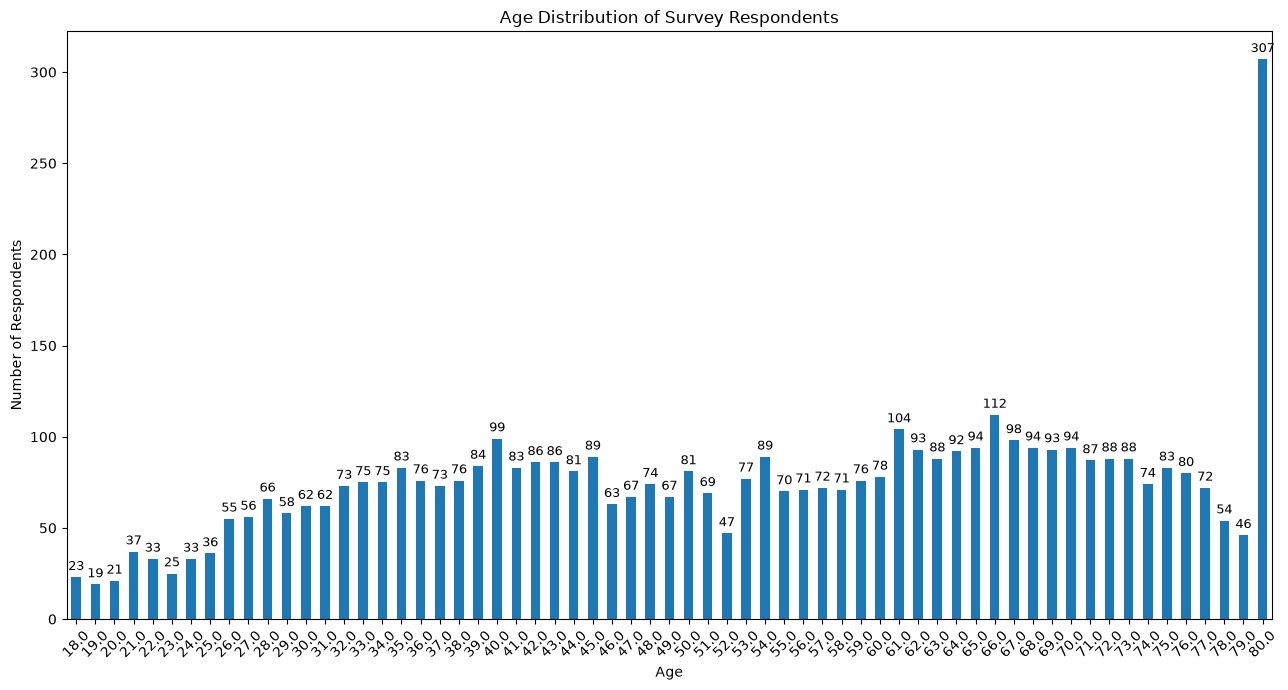

In [16]:
age_counts = finalvoting["age"].value_counts().sort_index()

ax = age_counts.plot(
    kind="bar",
    figsize=(13, 7),
    title="Age Distribution of Survey Respondents"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=9)

plt.xlabel("Age")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Here is a graph that shows the frequency of specific ages across the survey; one thing to note is that the data takes averyone over 80 and puts them into 1 column, so we don't have specific ages after 80. I don't appreciate this, as it would've been interesting to see how far we can get the opinions range from ages. Overall, there's a good spread of responses from different ages so we're not stuck to a single generation.

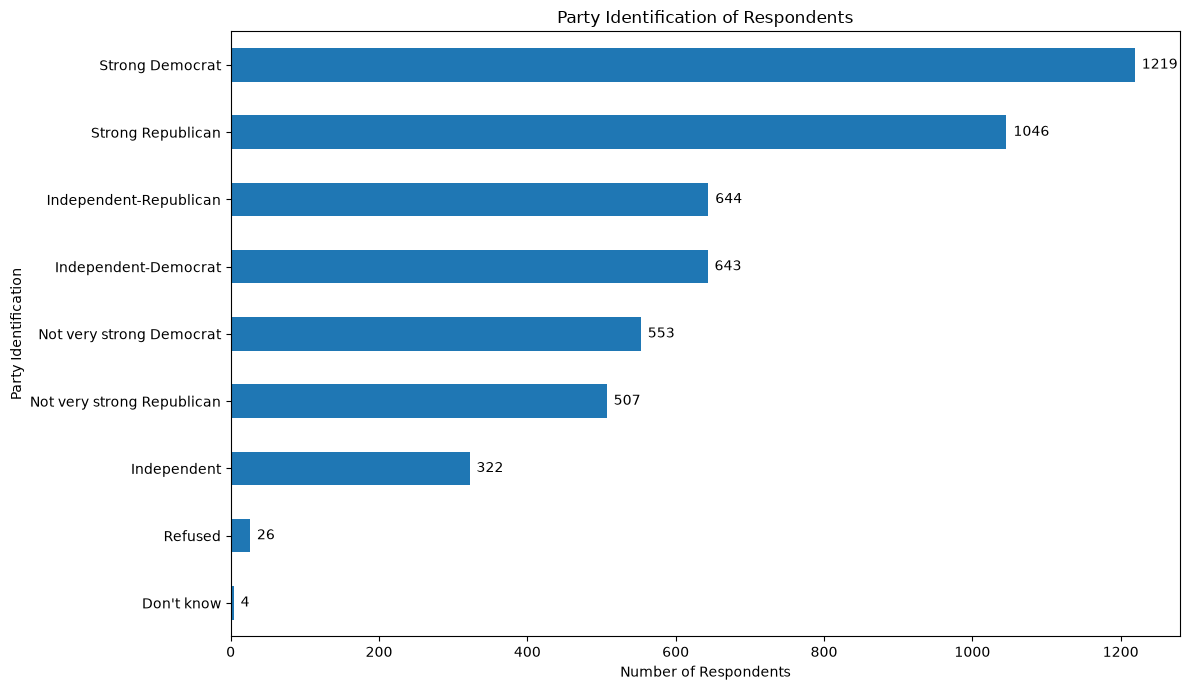

In [17]:

party_counts = finalvoting["party_identification"].value_counts()

ax = party_counts.sort_values().plot(
    kind="barh",
    figsize=(12, 7),
    title="Party Identification of Respondents"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=5)

plt.xlabel("Number of Respondents")
plt.ylabel("Party Identification")
plt.tight_layout()
plt.show()


This chart shows the frequency of folks' party identitfication with labels showing most respondants were strong democrats or strong republicans. For the presentation I'd want to show this plus a graph on how many folks within these top two categories had voted across party lines despite stating strong feelings to their identified party.  

#### Good relationships I plan to examine further

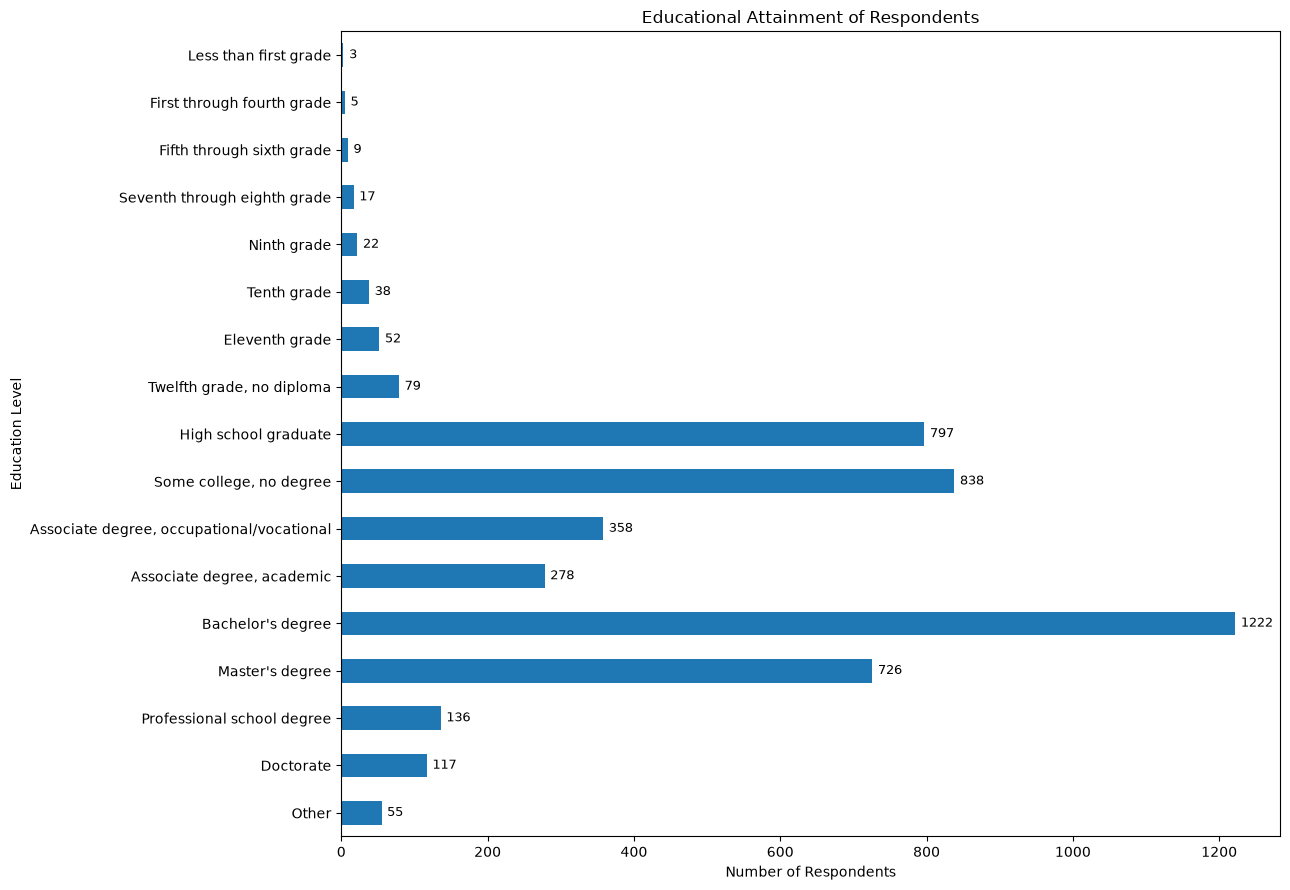

In [18]:

education_order = [
    "Less than first grade",
    "First through fourth grade",
    "Fifth through sixth grade",
    "Seventh through eighth grade",
    "Ninth grade",
    "Tenth grade",
    "Eleventh grade",
    "Twelfth grade, no diploma",
    "High school graduate",
    "Some college, no degree",
    "Associate degree, occupational/vocational",
    "Associate degree, academic",
    "Bachelor's degree",
    "Master's degree",
    "Professional school degree",
    "Doctorate",
    "Other"
]

education_counts = finalvoting["education"].value_counts().reindex(
    education_order
).dropna()

ax = education_counts.plot(
    kind="barh",
    figsize=(13, 9),
    title="Educational Attainment of Respondents"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4, fontsize=9)

plt.xlabel("Number of Respondents")
plt.ylabel("Education Level")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


expexplain this one 

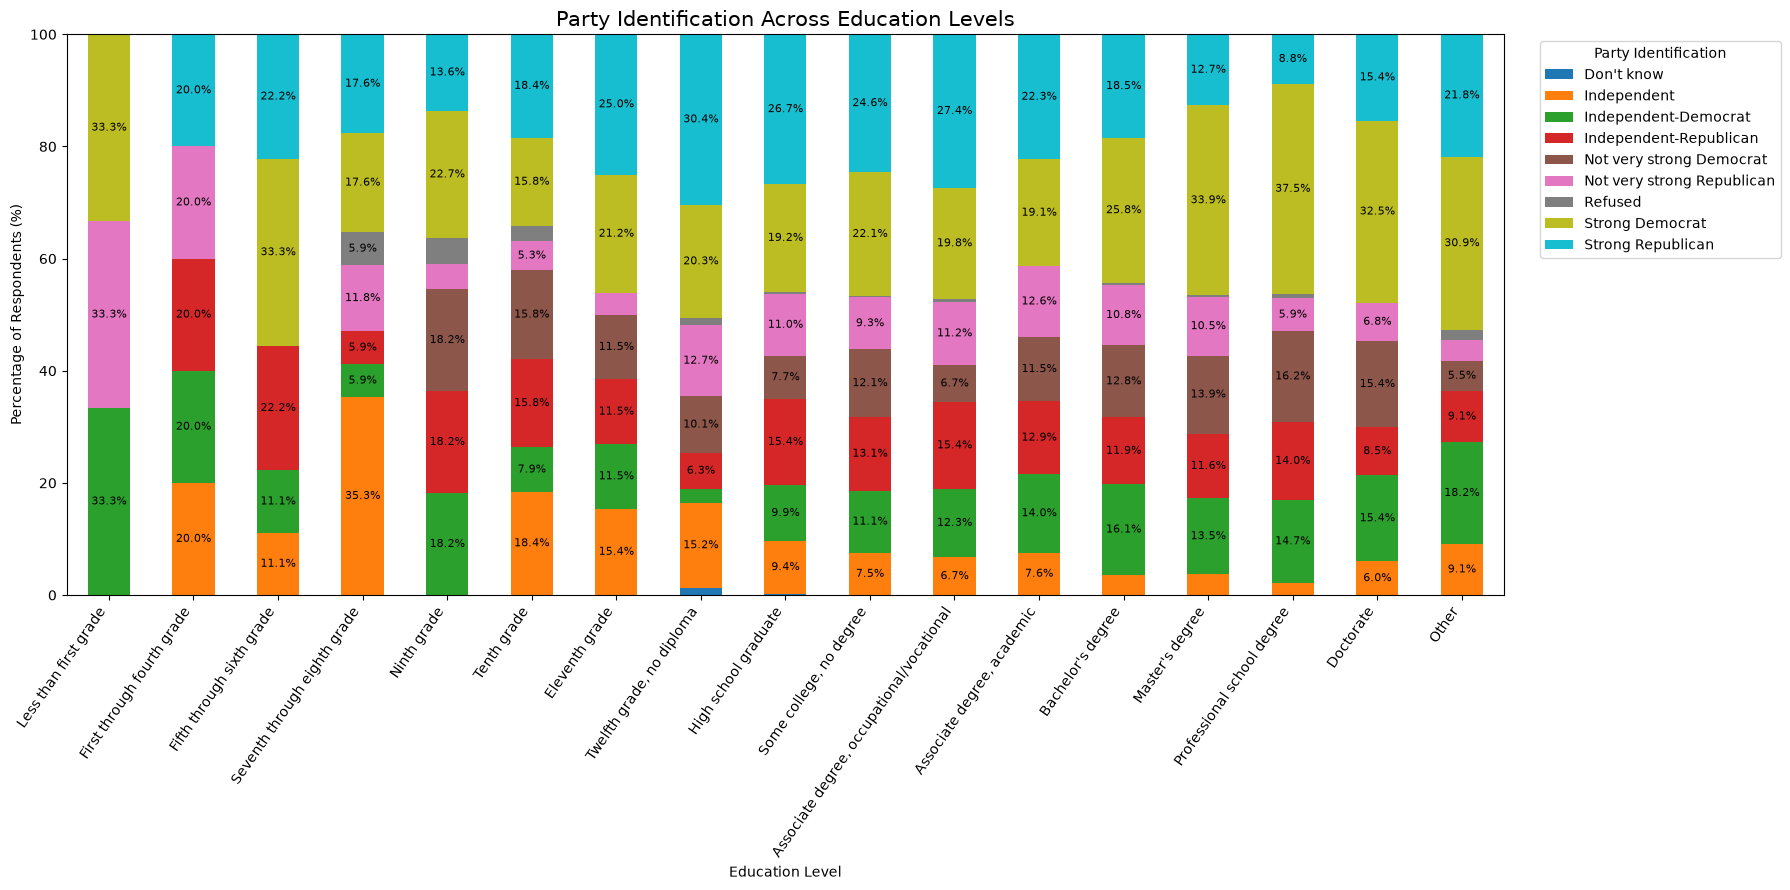

In [19]:
education_order = [
    "Less than first grade",
    "First through fourth grade",
    "Fifth through sixth grade",
    "Seventh through eighth grade",
    "Ninth grade",
    "Tenth grade",
    "Eleventh grade",
    "Twelfth grade, no diploma",
    "High school graduate",
    "Some college, no degree",
    "Associate degree, occupational/vocational",
    "Associate degree, academic",
    "Bachelor's degree",
    "Master's degree",
    "Professional school degree",
    "Doctorate",
    "Other"
]

education_party = pd.crosstab(
    finalvoting["education"],
    finalvoting["party_identification"],
    normalize="index"
) * 100

education_party = education_party.reindex(
    [x for x in education_order if x in education_party.index]
)

ax = education_party.plot(
    kind="bar",
    stacked=True,
    figsize=(18, 9),
    colormap="tab10"
)

for container in ax.containers:
    labels = [
        f"{bar.get_height():.1f}%" if bar.get_height() >= 5 else ""
        for bar in container
    ]
    ax.bar_label(container, labels=labels, label_type="center", fontsize=8)

plt.title("Party Identification Across Education Levels", fontsize=15)
plt.xlabel("Education Level")
plt.ylabel("Percentage of Respondents (%)")
plt.xticks(rotation=55, ha="right")
plt.legend(title="Party Identification", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


The above graphs the education level of ratio within each of the answer options. This was a tricky graph that definitely required AI help in how to parse so many categories in a succient way, and it helps me practice the pd.crosstab + normalization, which is a question I did get wrong in some of the quizes within the course. Overall, we see that there is a strong visual pattern, with some portion of the bar not making sense. I see a pattern where at eductation grows, so does the faction of strong democrat/strong repbulican, while some bars like the seventh through eigth grade bar has a very steep jump of independent, that disappears in ninth grade education level. I'd have to do some investigation as to why this is occuring. 

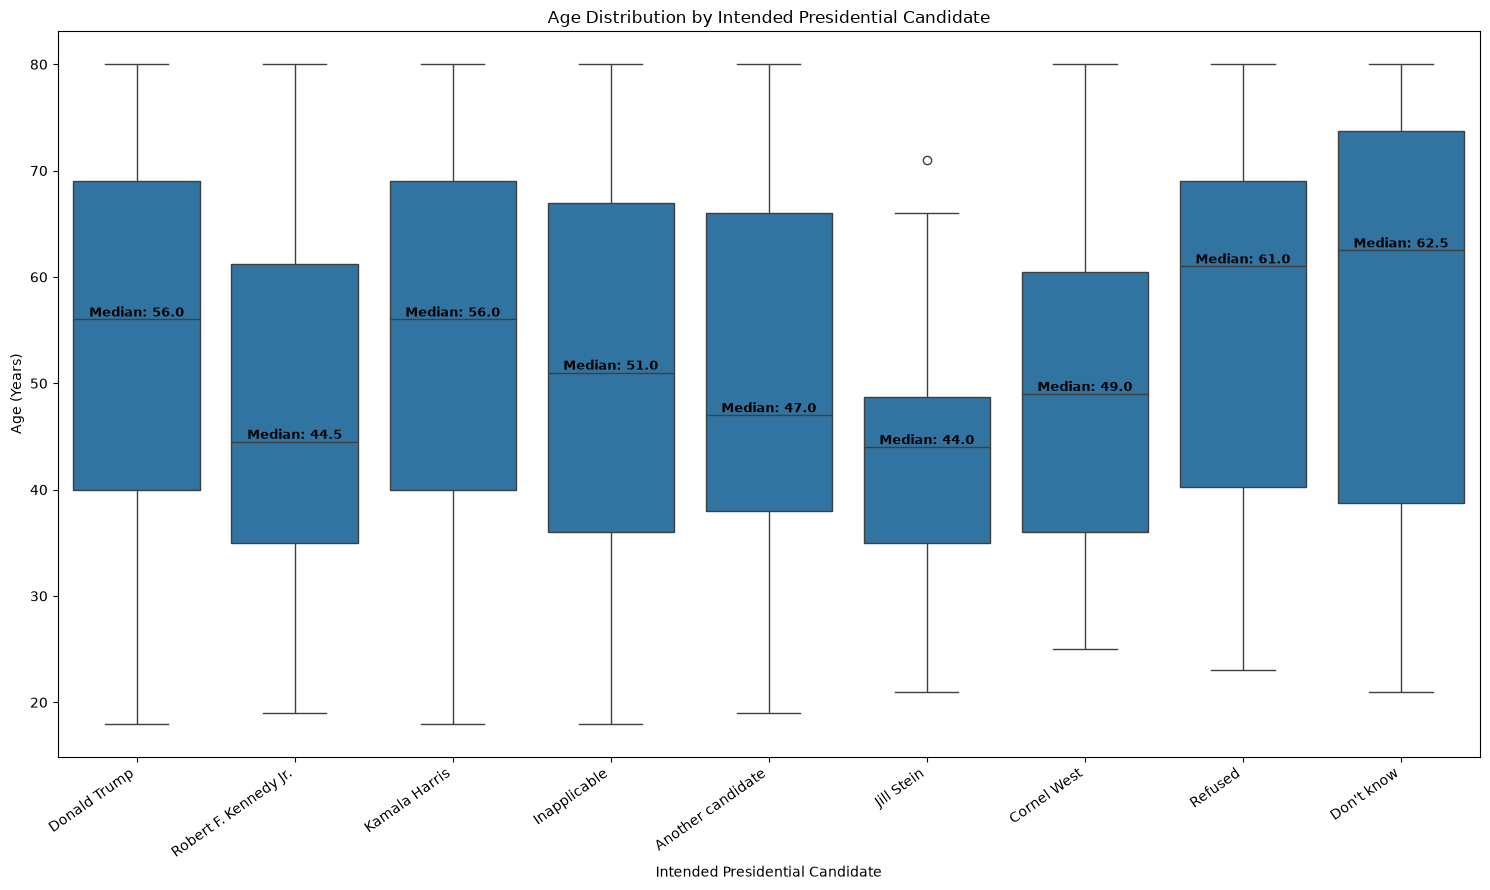

In [20]:
age_candidate = finalvoting[
    finalvoting["age"] != "80 years or older"
].copy()

age_candidate["age"] = pd.to_numeric(
    age_candidate["age"], errors="coerce"
)

age_candidate = age_candidate.dropna(
    subset=["age", "intended_presidential_candidate"]
)

plt.figure(figsize=(15, 9))

ax = sns.boxplot(
    data=age_candidate,
    x="intended_presidential_candidate",
    y="age"
)

medians = age_candidate.groupby(
    "intended_presidential_candidate"
)["age"].median()

for position, candidate in enumerate(ax.get_xticklabels()):
    median = medians.get_text() if False else medians.get(candidate.get_text())
    if pd.notna(median):
        ax.text(
            position,
            median,
            f"Median: {median:.1f}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )

plt.title("Age Distribution by Intended Presidential Candidate")
plt.xlabel("Intended Presidential Candidate")
plt.ylabel("Age (Years)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


This leans to the basic summary graphs and is a callback to some of the first assignments, but I found this type of graph helpful in having a immediate visual read on a section of the dataset; here I can see the average age of the voter for a candidate, and I can see immediately that the average age for some candidates range low (like Jill Stein) and some had large spans/intervals (a lot of people had done don't know before the polling began). I think getting a further look into how a person's response changed after the election, and looking at what age range changed their mind the most, would be a good study for the next step in this project.

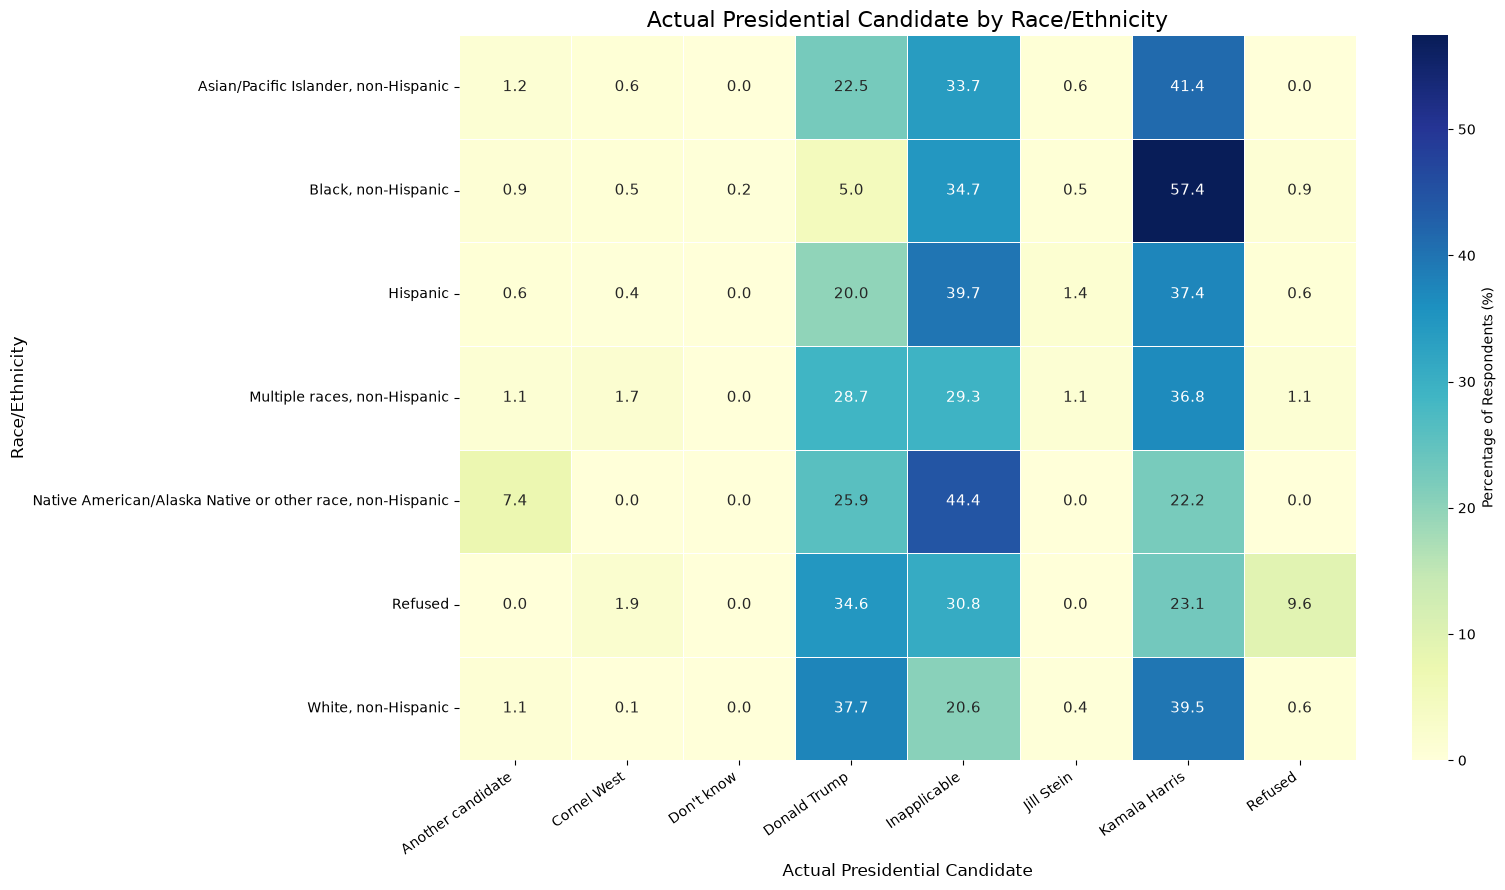

In [21]:
race_candidate = pd.crosstab(
    finalvoting["race_ethnicity"],
    finalvoting["actual_presidential_candidate"],
    normalize="index"
) * 100

plt.figure(figsize=(16, 9))

sns.heatmap(
    race_candidate,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    annot_kws={"size": 11},
    cbar_kws={"label": "Percentage of Respondents (%)"}
)

plt.title("Actual Presidential Candidate by Race/Ethnicity", fontsize=16)
plt.xlabel("Actual Presidential Candidate", fontsize=12)
plt.ylabel("Race/Ethnicity", fontsize=12)

plt.xticks(rotation=35, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.show()


This heat map required ai assistance, and was a great map to use for all the labels and cross labeling; a breakdown of each candidates and percentage of folks who voted for them in each ethnic/race category. I think the best part of this map is the color scheme tells us more than what the actual numbers show, which is super helpful when having readers/users look at it at a glance for a quick read. I see the two candidates with the most votes also having the darkest colors in their row (both Donald Trump and Kamala Harris). 